In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

sys.path.insert(0, "../src")   # shared grid + map helpers live in src/grid.py
from grid import LON_MIN, LON_MAX, LAT_MIN, LAT_MAX, RES, lon_edges, lat_edges, proj, style_map
from grid import nx as NX, ny as NY

In [2]:
DATA_DIR = Path("../data")      # data, tables, results (parquet, npz, csv, json)
FIG_DIR  = Path("../figures")   # all figures (png)

# Each notebook writes to its own subfolder; inputs come from earlier notebooks' folders
OUT_DIR = DATA_DIR / "05_data_denial"
FIG_OUT = FIG_DIR / "05_data_denial"
DIR_03  = DATA_DIR / "03_aggregation_and_means"       # agg_vel / agg_sst, weighting_diff
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_OUT.mkdir(parents=True, exist_ok=True)

In [3]:
# --- Data-denial settings ---
TARGET = 10                      # precision target (cm/s), as in the Method
MIN_TEST_DRIFTERS = 60           # largest fair subsample (30) ≈ median grid cell (31)
KS = [3, 5, 10, 15, 20, 30]      # drifters kept per subsample (30 ≈ the median cell's 31 drifters)
B = 500                          # subsamples per grid cell per k
SEED = 20261105                  # same seed as the bootstrap (04); stream 3 = data denial
REGIONS = ["jet", "recirculation"]

In [4]:
agg_vel = pd.read_parquet(DIR_03 / "agg_vel_1deg.parquet")

# Combine ENSO phases: one row per (cell, drifter) for the all-data climatology
drift = agg_vel.groupby(["iy", "ix", "id"], as_index=False)[["n", "sum_ve", "sum_vn"]].sum()
print(f"{len(drift):,} drifter-cell rows")

22,932 drifter-cell rows


In [5]:
# Each drifter's own mean velocity in its grid cell
drift["ve_d"] = drift["sum_ve"] / drift["n"]
drift["vn_d"] = drift["sum_vn"] / drift["n"]

g = drift.groupby(["iy", "ix"])
cells = pd.DataFrame({
    "n_drifters": g.size(),                                   # distinct drifters
    "mean_ve":    g["sum_ve"].sum() / g["n"].sum(),           # full-data (hour-weighted) mean
    "mean_vn":    g["sum_vn"].sum() / g["n"].sum(),
    "spread":     np.sqrt(g["ve_d"].var() + g["vn_d"].var()), # how much drifters disagree (NaN if 1 drifter)
})
cells["mean_speed"] = np.hypot(cells["mean_ve"], cells["mean_vn"])

print(f"median drifters per grid cell: {cells['n_drifters'].median():.0f}")

median drifters per grid cell: 31


In [6]:
# A cell can only be fairly tested up to half its drifters, so the threshold sets the largest k
for thr in [40, 60, 80]:
    print(f"≥{thr} drifters: {(cells['n_drifters'] >= thr).sum()} grid cells "
          f"(largest fair subsample: {thr // 2})")

≥40 drifters: 211 grid cells (largest fair subsample: 20)
≥60 drifters: 100 grid cells (largest fair subsample: 30)
≥80 drifters: 51 grid cells (largest fair subsample: 40)


In [7]:
test = cells[cells["n_drifters"] >= MIN_TEST_DRIFTERS].copy()
print(f"test cells: {len(test)}")

test cells: 100


threshold (Otsu): 0.34 m/s
               count  mean   std   min   10%   50%   90%   max
region                                                        
jet             35.0  0.53  0.16  0.35  0.39  0.46  0.75  0.90
recirculation   65.0  0.15  0.10  0.01  0.04  0.12  0.30  0.32


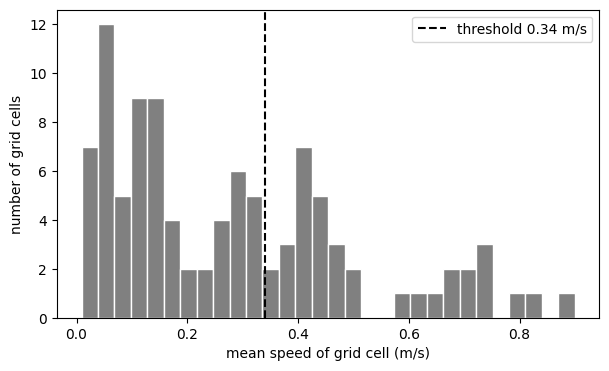

In [8]:
# Test every split point and keep the one that best separates fast and slow cells
speeds = np.sort(test["mean_speed"].values)
best_thr, best_score = None, -np.inf
for thr in (speeds[:-1] + speeds[1:]) / 2:                   # midpoints between neighbouring cells
    slow, fast = speeds[speeds < thr], speeds[speeds >= thr]
    w1, w2 = len(slow) / len(speeds), len(fast) / len(speeds)
    score = w1 * w2 * (slow.mean() - fast.mean()) ** 2       # between-group variance
    if score > best_score:
        best_thr, best_score = thr, score

JET_SPEED = round(best_thr, 2)
test["region"] = np.where(test["mean_speed"] >= JET_SPEED, "jet", "recirculation")

print(f"threshold (Otsu): {JET_SPEED} m/s")
print(test.groupby("region")["mean_speed"].describe(percentiles=[0.1, 0.5, 0.9]).round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(speeds, bins=30, color="grey", edgecolor="white")
ax.axvline(JET_SPEED, color="k", ls="--", label=f"threshold {JET_SPEED} m/s")
ax.set_xlabel("mean speed of grid cell (m/s)"); ax.set_ylabel("number of grid cells")
ax.legend()
fig.savefig(FIG_OUT / "otsu_speed_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
records = []
for (iy, ix), row in test.iterrows():
    d = drift[(drift["iy"] == iy) & (drift["ix"] == ix)]          # this grid cell's drifters
    n_h, s_ve, s_vn = d["n"].values, d["sum_ve"].values, d["sum_vn"].values
    N = len(d)
    rng = np.random.default_rng(np.random.SeedSequence([SEED, int(iy), int(ix), 3]))   # per-cell stream
    for k in KS:
        if k > N / 2:                                              # only fair subsamples
            continue
        idx = np.argsort(rng.random((B, N)), axis=1)[:, :k]        # B picks of k different drifters
        hrs = n_h[idx].sum(axis=1)
        ve = s_ve[idx].sum(axis=1) / hrs                            # subsample means
        vn = s_vn[idx].sum(axis=1) / hrs
        err = np.hypot(ve - row["mean_ve"], vn - row["mean_vn"])    # distance from full-cell mean (m/s)
        records.append({"iy": iy, "ix": ix, "region": row["region"], "k": k,
                        "spread": row["spread"], "N": N,
                        "err_median": np.median(err), "err95": np.percentile(err, 95)})

dd = pd.DataFrame(records)
# Finite-population correction: k of N drifters are part of the full-cell mean they are compared with
dd["err95_fpc"] = dd["err95"] / np.sqrt(1 - dd["k"] / dd["N"])
print(f"{len(dd)} results from {dd[['iy', 'ix']].drop_duplicates().shape[0]} grid cells")

# Exact median 95% error (cm/s) by region and k, for the Results text
median_e95 = {col: (dd.groupby(["region", "k"])[col].median() * 100).unstack("k")
              for col in ["err95", "err95_fpc"]}
for col, t in median_e95.items():
    print(f"{col}:\n{t.round(1)}\n")

600 results from 100 grid cells
err95:
k                3     5     10    15    20    30
region                                           
jet            58.3  46.1  29.4  23.8  19.3  15.2
recirculation  35.6  25.2  16.3  12.3   9.9   6.9

err95_fpc:
k                3     5     10    15    20    30
region                                           
jet            59.6  47.9  30.4  25.4  21.4  17.5
recirculation  36.5  26.0  17.8  13.8  11.8   9.1



In [10]:
# Fit log(error) = a + b*log(k) to the median curve of each region, then solve for the target
def fit_n_star(col):
    fits = {}
    for region in REGIONS:
        med = dd[dd["region"] == region].groupby("k")[col].median() * 100   # cm/s
        b, a = np.polyfit(np.log(med.index), np.log(med.values), 1)        # slope, intercept
        fits[region] = {"slope": float(b), "intercept": float(a),
                        "N_star": int(np.ceil(np.exp((np.log(TARGET) - a) / b)))}
    return fits

fits = {"uncorrected": fit_n_star("err95"), "fpc": fit_n_star("err95_fpc")}
N_star = {r: fits["fpc"][r]["N_star"] for r in REGIONS}                    # primary: FPC-corrected
N_star_uncorrected = {r: fits["uncorrected"][r]["N_star"] for r in REGIONS}
for version, f in fits.items():
    for region in REGIONS:
        print(f"{version:>11} {region:>13}: slope {f[region]['slope']:.2f} (1/√k would be -0.50), "
              f"N* for ±{TARGET} cm/s = {f[region]['N_star']}")

uncorrected           jet: slope -0.59 (1/√k would be -0.50), N* for ±10 cm/s = 62
uncorrected recirculation: slope -0.70 (1/√k would be -0.50), N* for ±10 cm/s = 20
        fpc           jet: slope -0.54 (1/√k would be -0.50), N* for ±10 cm/s = 83
        fpc recirculation: slope -0.59 (1/√k would be -0.50), N* for ±10 cm/s = 26


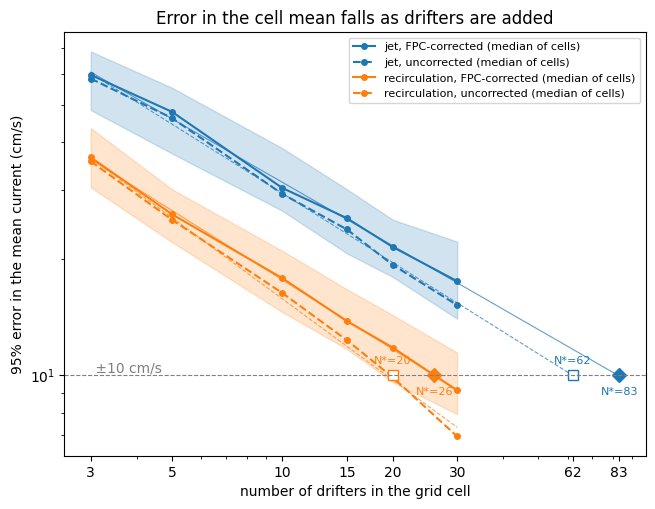

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
k_line = {}
for region, colour in [("jet", "tab:blue"), ("recirculation", "tab:orange")]:
    for col, ls, label in [("err95_fpc", "-", "FPC-corrected"), ("err95", "--", "uncorrected")]:
        s = dd[dd["region"] == region].groupby("k")[col]
        med = s.median() * 100
        ax.plot(med.index, med.values, marker="o", ls=ls, color=colour, ms=4,
                label=f"{region}, {label} (median of cells)")
        if col == "err95_fpc":                                     # IQR band for the primary curve
            ax.fill_between(med.index, s.quantile(0.25) * 100, s.quantile(0.75) * 100,
                            color=colour, alpha=0.2)
        f = fits["uncorrected" if col == "err95" else "fpc"][region]
        k_fit = np.geomspace(KS[0], max(f["N_star"], KS[-1]), 50)   # fitted line out to N*
        ax.plot(k_fit, np.exp(f["intercept"] + f["slope"] * np.log(k_fit)),
                ls=ls, color=colour, lw=0.8, alpha=0.7)
        ax.plot(f["N_star"], TARGET, marker="D" if col == "err95_fpc" else "s", ms=7,
                mfc=colour if col == "err95_fpc" else "white", mec=colour, ls="none")
        ax.annotate(f"N*={f['N_star']}", (f["N_star"], TARGET), textcoords="offset points",
                    xytext=(0, -14 if col == "err95_fpc" else 8), ha="center", fontsize=8, color=colour)

ax.axhline(TARGET, color="grey", ls="--", lw=0.8)
ax.text(KS[0], TARGET, f" ±{TARGET} cm/s", va="bottom", color="grey")
ax.set_xscale("log"); ax.set_yscale("log")
ticks = sorted(set(KS) | {max(N_star.values()), max(N_star_uncorrected.values())})
ax.set_xticks(ticks); ax.set_xticklabels(ticks)
ax.set_xlabel("number of drifters in the grid cell")
ax.set_ylabel("95% error in the mean current (cm/s)")
ax.set_title("Error in the cell mean falls as drifters are added")
ax.legend(fontsize=8)
fig.savefig(FIG_OUT / "data_denial_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
N_STAR = N_star                                     # FPC-corrected fit: primary result, used by notebook 06

cells["region"] = np.where(cells["mean_speed"] >= JET_SPEED, "jet", "recirculation")
cells["N_star"] = cells["region"].map(N_STAR)
cells["meets_N_star"] = cells["n_drifters"] >= cells["N_star"]
cells["drifters_needed"] = (cells["N_star"] - cells["n_drifters"]).clip(lower=0)   # extra drifters to reach N*

# Same with the uncorrected N* (kept for comparison; not used downstream)
cells["N_star_uncorrected"] = cells["region"].map(N_star_uncorrected)
cells["meets_N_star_uncorrected"] = cells["n_drifters"] >= cells["N_star_uncorrected"]
cells["drifters_needed_uncorrected"] = (cells["N_star_uncorrected"] - cells["n_drifters"]).clip(lower=0)

print(cells.groupby("region")["meets_N_star"].mean().map("{:.0%}".format).rename("cells meeting N*"))
print(f"all grid cells meeting N*: {cells['meets_N_star'].mean():.0%}")
print(cells.loc[~cells["meets_N_star"]].groupby("region")["drifters_needed"].median()
      .rename("median extra drifters needed (cells short of N*)"))

def n_star_stats(meets, needed):
    short = ~cells[meets]
    return {"share_meeting_overall": round(float(cells[meets].mean()), 4),
            "share_meeting_by_region": {r: round(float(v), 4)
                                        for r, v in cells.groupby("region")[meets].mean().items()},
            "median_extra_drifters_short": {r: float(v) for r, v in
                                            cells.loc[short].groupby("region")[needed].median().items()}}

coverage = n_star_stats("meets_N_star", "drifters_needed")                              # primary (FPC)
coverage_uncorrected = n_star_stats("meets_N_star_uncorrected", "drifters_needed_uncorrected")
print("uncorrected:", coverage_uncorrected)

region
jet              43%
recirculation    60%
Name: cells meeting N*, dtype: str
all grid cells meeting N*: 58%
region
jet              34.0
recirculation     9.0
Name: median extra drifters needed (cells short of N*), dtype: float64
uncorrected: {'share_meeting_overall': 0.7227, 'share_meeting_by_region': {'jet': 0.6111, 'recirculation': 0.7338}, 'median_extra_drifters_short': {'jet': 16.0, 'recirculation': 8.0}}


In [13]:
# --- Single-relationship test (Method 4.5): E95 ≈ C · spread / √k, one C for all cells and k ---
def single_relationship(col):
    obs = dd[col]
    x = np.log(dd["spread"]) - 0.5 * np.log(dd["k"])
    log_C = float(np.mean(np.log(obs) - x))                 # least squares on log values, slope fixed
    ratio = obs / (np.exp(log_C) * dd["spread"] / np.sqrt(dd["k"]))
    table = ratio.groupby([dd["region"], dd["k"]]).median().unstack("k")
    return log_C, table

single = {}
for version, col in [("uncorrected", "err95"), ("fpc", "err95_fpc")]:
    log_C, table = single_relationship(col)
    single[version] = {"C": round(float(np.exp(log_C)), 4), "median_ratio_obs_to_pred": table}
    print(f"{version}: C = {np.exp(log_C):.3f}; median observed / predicted E95:\n{table.round(2)}\n")

for version, s in single.items():
    t = s["median_ratio_obs_to_pred"]
    print(f"{version}: model over-predicts recirculation cells (ratio < 1) at "
          f"{(t.loc['recirculation'] < 1).sum()} of {t.shape[1]} k values; "
          f"jet ratio range {t.loc['jet'].min():.2f}-{t.loc['jet'].max():.2f}")

uncorrected: C = 1.553; median observed / predicted E95:
k                3     5     10    15    20    30
region                                           
jet            1.32  1.27  1.25  1.14  1.13  1.05
recirculation  1.05  0.97  0.89  0.82  0.77  0.69

fpc: C = 1.711; median observed / predicted E95:
k                3     5     10    15    20    30
region                                           
jet            1.21  1.18  1.21  1.15  1.11  1.12
recirculation  0.97  0.91  0.86  0.83  0.83  0.81

uncorrected: model over-predicts recirculation cells (ratio < 1) at 5 of 6 k values; jet ratio range 1.05-1.32
fpc: model over-predicts recirculation cells (ratio < 1) at 6 of 6 k values; jet ratio range 1.11-1.21


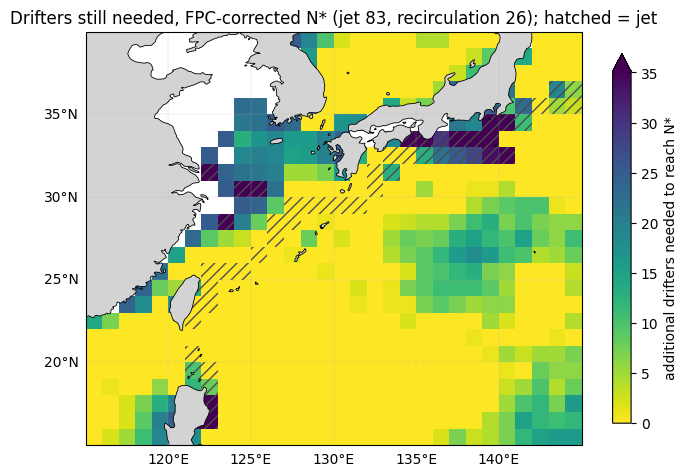

In [14]:
def to_grid(col, fill=np.nan, dtype=float):
    out = np.full((NY, NX), fill, dtype=dtype)
    iy, ix = cells.index.get_level_values("iy"), cells.index.get_level_values("ix")
    out[iy, ix] = cells[col].values
    return out

np.savez(OUT_DIR / "data_denial_1deg.npz",
         is_jet=to_grid("mean_speed") >= JET_SPEED,
         N_star=to_grid("N_star"),
         meets_N_star=to_grid("meets_N_star", fill=False, dtype=bool),
         drifters_needed=to_grid("drifters_needed"),
         N_star_jet=N_STAR["jet"], N_star_recirc=N_STAR["recirculation"],
         target_cm=TARGET, jet_speed=JET_SPEED, min_test_drifters=MIN_TEST_DRIFTERS,
         # Uncorrected alternative, kept for comparison (primary keys above are FPC-corrected)
         N_star_uncorrected=to_grid("N_star_uncorrected"),
         meets_N_star_uncorrected=to_grid("meets_N_star_uncorrected", fill=False, dtype=bool),
         drifters_needed_uncorrected=to_grid("drifters_needed_uncorrected"),
         N_star_jet_uncorrected=N_star_uncorrected["jet"],
         N_star_recirc_uncorrected=N_star_uncorrected["recirculation"])
dd.to_csv(OUT_DIR / "data_denial_results.csv", index=False)

# --- Map: extra drifters needed (0 where N* is met); jet cells hatched ---
fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": proj})
m = ax.pcolormesh(lon_edges, lat_edges, to_grid("drifters_needed"), cmap="viridis_r",
                  vmin=0, vmax=np.nanpercentile(cells["drifters_needed"], 98), transform=proj)
for iy, ix in cells.index[cells["region"] == "jet"]:
    ax.add_patch(Rectangle((lon_edges[ix], lat_edges[iy]), RES, RES, fill=False, hatch="///",
                           edgecolor="0.3", lw=0, transform=proj, zorder=1.5))
fig.colorbar(m, ax=ax, shrink=0.8, extend="max", label="additional drifters needed to reach N*")
style_map(ax, f"Drifters still needed, FPC-corrected N* (jet {N_STAR['jet']}, "
              f"recirculation {N_STAR['recirculation']}); hatched = jet")
fig.savefig(FIG_OUT / "n_star_map.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
# --- Key numbers for the Results ---
def table_json(t):
    return {r: {str(k): round(float(v), 2) for k, v in row.items()} for r, row in t.iterrows()}

grp = test.groupby("region")["mean_speed"]
summary = {
    "n_test_cells": {"total": int(len(test)), **{r: int(v) for r, v in test["region"].value_counts().items()}},
    "primary": "fpc_corrected",
    "min_test_drifters": MIN_TEST_DRIFTERS, "ks": KS, "B": B, "seed": SEED, "target_cmps": TARGET,
    "otsu_threshold_ms": JET_SPEED,
    "test_mean_speed_ms": {r: {"median": round(float(grp.median()[r]), 3),
                               "min": round(float(grp.min()[r]), 3),
                               "max": round(float(grp.max()[r]), 3)} for r in REGIONS},
    "median_E95_cmps": table_json(median_e95["err95_fpc"]),
    "median_E95_cmps_uncorrected": table_json(median_e95["err95"]),
    "slopes": {r: round(fits["fpc"][r]["slope"], 3) for r in REGIONS},
    "slopes_uncorrected": {r: round(fits["uncorrected"][r]["slope"], 3) for r in REGIONS},
    "N_star": N_star,
    "N_star_uncorrected": N_star_uncorrected,
    "n_velocity_cells": int(len(cells)),
    "coverage": coverage,
    "coverage_uncorrected": coverage_uncorrected,
    "single_relationship": {"fpc_corrected" if v == "fpc" else v:
                            {"C": s["C"], "median_ratio_obs_to_pred": table_json(s["median_ratio_obs_to_pred"])}
                            for v, s in single.items()},
}
(OUT_DIR / "05_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "n_test_cells": {
    "total": 100,
    "recirculation": 65,
    "jet": 35
  },
  "primary": "fpc_corrected",
  "min_test_drifters": 60,
  "ks": [
    3,
    5,
    10,
    15,
    20,
    30
  ],
  "B": 500,
  "seed": 20261105,
  "target_cmps": 10,
  "otsu_threshold_ms": 0.34,
  "test_mean_speed_ms": {
    "jet": {
      "median": 0.458,
      "min": 0.351,
      "max": 0.9
    },
    "recirculation": {
      "median": 0.125,
      "min": 0.009,
      "max": 0.319
    }
  },
  "median_E95_cmps": {
    "jet": {
      "3": 59.62,
      "5": 47.87,
      "10": 30.43,
      "15": 25.43,
      "20": 21.44,
      "30": 17.48
    },
    "recirculation": {
      "3": 36.51,
      "5": 26.03,
      "10": 17.8,
      "15": 13.79,
      "20": 11.78,
      "30": 9.13
    }
  },
  "median_E95_cmps_uncorrected": {
    "jet": {
      "3": 58.33,
      "5": 46.12,
      "10": 29.38,
      "15": 23.79,
      "20": 19.27,
      "30": 15.16
    },
    "recirculation": {
      "3": 35.65,
      "5": 